In [230]:
import numpy as np
import pandas as pd
import optuna
import plotly.express as px
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_auc_score
from lightgbm import LGBMClassifier

# Загрузим данные

- Данные упорядочены по времени
- Задача - предсказать `target`
- Фичи - `feature_i`
- Трейн, валидация и тест уже определены (см. колонку `sample_part`)

In [231]:
df = pd.read_parquet('df.parquet.gzip')
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 500000 entries, 22620 to 310653
Columns: 235 entries, date to sample_part
dtypes: category(2), datetime64[ms](1), datetime64[ns](2), float64(220), int64(9), object(1)
memory usage: 893.6+ MB


In [232]:
df.head()

,date,month,quarter,feature_217,feature_66,feature_9,feature_193,feature_15,feature_199,feature_25,...,feature_20,feature_188,feature_71,feature_106,feature_14,feature_92,feature_179,feature_102,target,sample_part
22620,2021-01-01,2021-01-01,2021-01-01,1.180855,0.483118,13.976791,1.135021,43.271792,-46.888875,97.558366,...,23.745198,-32.001093,85.489903,1.454045,-195.725786,3.719083,1,-28.813537,0.0,train
478621,2021-01-01,2021-01-01,2021-01-01,3.427814,0.886778,27.158209,-0.378728,80.087863,-67.242703,105.803406,...,22.902111,-37.436243,71.735619,1.657242,-176.250404,3.277817,1,-45.987721,1.0,train
372254,2021-01-01,2021-01-01,2021-01-01,-38.555018,1.227175,19.893873,0.498787,98.464365,-67.402522,81.858076,...,21.848414,-51.872841,65.363236,1.626874,-178.116798,2.028950,0,-31.074122,1.0,train
2596,2021-01-01,2021-01-01,2021-01-01,-14.666558,0.753129,18.203010,-1.200014,117.331340,-25.557745,90.277266,...,26.134586,-49.703003,65.013659,1.170023,-192.232264,2.218177,1,-36.703897,0.0,train
216892,2021-01-01,2021-01-01,2021-01-01,6.734990,1.129100,11.245920,-0.108955,61.205722,-78.397406,82.637472,...,24.201039,-41.070219,69.986127,1.630795,-200.155528,3.055104,1,-44.672299,1.0,train


In [233]:
TARGET = 'target'
N_FEATURES = 230
features = [f'feature_{i}' for i in range(N_FEATURES)]

# Первичный отбор признаков... (1 балл)

**Задание:** Сначала отсеем совсем уж мусорные признаки.

Воспользовавшись вашим кодом для вычисления `IV` из прошлой домашки, для всех **числовых** фичей вычислите `IV` на 20 бакетах. Отсейте признаки с `IV < 0.005`.

**Hint:** паркет не всегда сохраняет `dtype` колонки. Чтобы проверить признаки на "реальный" тип данных, лучше на всякий случай посмотреть на `nunique` 

In [234]:
# your code here
from typing import Union
from scipy.special import logit

def calc_buckets(x : Union[np.ndarray, pd.Series], n_buckets : int) -> np.ndarray:
    """Разбивает массив значений признака x на 
    n_buckets бакетов"""

    x = pd.Series(x).reset_index(drop=True)
    buckets = x.rank(method="dense", pct=True) * n_buckets
    buckets = np.ceil(buckets) - 1   # np.floor дает другой результат для 5.0, 6.0 и т.д.
    buckets = np.array(buckets, dtype=np.int16)

    return buckets
def woe_transform(badrate : float, offset : float) -> float:
    """Считаем WoE для бакета с данным badrate и выборки
    с данным offset."""
    woe = logit(badrate) - offset
    return woe

def calc_IV(
        values : Union[np.ndarray, pd.Series],
        target : Union[np.ndarray, pd.Series],
        n_buckets : int
    ) -> float:
    buckets = calc_buckets(values, n_buckets)
    
    total = len(target)
    bads = target.sum()
    goods = total - bads
    offset = logit(target.mean())
    IV = sum(
            [
            ((bads_i := target[buckets == i].sum()) / bads - ((m := len(target[buckets == i])) - bads_i) / goods) * 
            woe_transform(bads_i / m, offset)   for i in sorted(set(buckets))
            ]
        ) # всё ещё простите за это...

    return IV

In [235]:
# В отдельную ячейку, потому что долго.
num_df_columns = [x for x in df.select_dtypes(include=['float64', 'int64']).columns if df[x].nunique() > 50  ]
target_train = df[TARGET][df['sample_part'] == 'train']
iv_arr = {}

In [236]:
for x in num_df_columns:
    val_raw = df[x][df['sample_part'] == 'train']
    val = np.asarray(val_raw)
    iv = calc_IV(val, target_train, 20)
    iv_arr[x] = iv 

c:\Users\temy2\AppData\Local\Programs\Python\Python310\lib\site-packages\pandas\core\series.py:1031: RuntimeWarning:

invalid value encountered in cast



In [244]:
iv_selected_features = [f for f, iv in iv_arr.items() if iv >= 0.005]
print(len(iv_selected_features), iv_selected_features)

57 ['feature_9', 'feature_15', 'feature_154', 'feature_218', 'feature_96', 'feature_223', 'feature_30', 'feature_225', 'feature_162', 'feature_167', 'feature_109', 'feature_124', 'feature_79', 'feature_213', 'feature_117', 'feature_38', 'feature_24', 'feature_75', 'feature_5', 'feature_56', 'feature_114', 'feature_139', 'feature_65', 'feature_142', 'feature_12', 'feature_35', 'feature_227', 'feature_115', 'feature_155', 'feature_132', 'feature_76', 'feature_97', 'feature_140', 'feature_135', 'feature_2', 'feature_46', 'feature_100', 'feature_111', 'feature_138', 'feature_164', 'feature_98', 'feature_36', 'feature_183', 'feature_27', 'feature_156', 'feature_4', 'feature_32', 'feature_206', 'feature_172', 'feature_70', 'feature_44', 'feature_23', 'feature_170', 'feature_39', 'feature_216', 'feature_94', 'feature_43']


**Вопрос**: Почему некорректно сравнивать `IV` у категориальных и числовых фичей?

Вычислите IV для категориальных фичей на `n` бакетах, где `n = min(число категорий фичи, 20)`. Возможно, придётся перекодировать некоторые фичи (*только не OneHot-ом!*)

*Опционально*: примените также и к категориальным фичам предварительный отбор по `IV` с менее строгим порогом

In [238]:
# your code here
cat_df_columns = [x for x in df.select_dtypes(include=['category', 'int64']).columns if df[x].nunique() <= 50 ]
cat_df_columns

['feature_147',
 'feature_144',
 'feature_168',
 'feature_165',
 'feature_31',
 'feature_0',
 'feature_209',
 'feature_222',
 'feature_37',
 'feature_157',
 'feature_179']

In [239]:
iv_selected_cat_features = {}
for y in cat_df_columns:
    val_raw = df[y][df['sample_part'] == 'train']
    val = np.asarray(val_raw)
    iv = calc_IV(val, target_train,  min(20, len(np.unique(val)) ))
    iv_selected_cat_features[y] = iv 

iv_selected_cat_features = [f for f, iv in iv_selected_cat_features.items() if iv >= 0.001]
len(iv_selected_cat_features), iv_selected_cat_features

(6,
 ['feature_147',
  'feature_144',
  'feature_168',
  'feature_165',
  'feature_31',
  'feature_209'])

**Ответ:** сравнивать IV у категориальных и числовых фичей некорректно, потому что мы теряем какую-то часть информации о непрерывных фичах из-за биннинга, потому что мы для корректного подсчёта IV мы должны относиться к ней, как к дискретной случайной величине, а тогда мы можем очень плохо поделить на бакеты, чтобы получить дискретность, и поэтому получить низкий IV, хотя проблема была не в самой фиче, а в разбиении на бакеты, категориальные фичи же в свою очередь от такой проблемы не страдают, потому что уже дискретны, поэтому для них IV не занижается.

# Бустинг

Используйте код для подбора гиперпараметров и обучения бустинга из предыдущей домашки

In [240]:
# В переменную features_optuna положите список признаков с предыдущего шага
features_optuna = iv_selected_features + iv_selected_cat_features
len(features_optuna)

63

In [117]:
import lightgbm as lgb

In [ ]:
import optuna

train_data_df = df[df['sample_part'] == 'train']
valid_data_df = df[df['sample_part'] == 'val']
train_data = lgb.Dataset(train_data_df[features_optuna], label=train_data_df[TARGET])
valid_data = lgb.Dataset(valid_data_df[features_optuna], label=valid_data_df[TARGET])

X_test = valid_data_df[features_optuna]

def objective(trial):
    params = {
        'objective': 'binary',
        'metric': 'auc',
        'verbosity': -1,
        'boosting_type': 'gbdt',
        'n_jobs' : -1,
        'random_state': 52,
        # TODO: задайте гиперпараметры через trial.suggest_*
        'num_leaves': trial.suggest_int('num_leaves', 10, 200),       # TODO
        'learning_rate': trial.suggest_float('learning_rate', 0.001, 0.3, log = True),    # TODO
        'feature_fraction': trial.suggest_float('feature_fraction', 0.5, 1, step=0.1), # TODO
    }

    # TODO: обучите модель с early stopping и верните AUC на валидации
    model = lgb.train(params=params, train_set=train_data, valid_sets=[valid_data], callbacks=[lgb.early_stopping(stopping_rounds=10)], num_boost_round=250)
    auc = roc_auc_score(valid_data_df[TARGET], model.predict(X_test))
    return auc


# TODO: создайте study и запустите optimize (n_trials >= 50)
study = optuna.create_study(direction = 'maximize')
study.optimize(objective, n_trials=50)

print("Best params:", study.best_params)
print("Best AUC:", study.best_value)

[I 2026-08-17 23:46:04,042] A new study created in memory with name: no-name-e5d55a89-b628-46ce-839b-3148b6456cde


Training until validation scores don't improve for 10 rounds
Did not meet early stopping. Best iteration is:
[249]	valid_0's auc: 0.741586


[I 2026-08-17 23:46:25,566] Trial 0 finished with value: 0.741585660514813 and parameters: {'num_leaves': 187, 'learning_rate': 0.03438680160033079, 'feature_fraction': 0.9}. Best is trial 0 with value: 0.741585660514813.


Training until validation scores don't improve for 10 rounds
Did not meet early stopping. Best iteration is:
[250]	valid_0's auc: 0.711093


[I 2026-08-17 23:46:40,941] Trial 1 finished with value: 0.7110930757649343 and parameters: {'num_leaves': 141, 'learning_rate': 0.007207996247295782, 'feature_fraction': 0.7}. Best is trial 0 with value: 0.741585660514813.


...

Early stopping, best iteration is:
[53]	valid_0's auc: 0.73148
Training until validation scores don't improve for 10 rounds
Did not meet early stopping. Best iteration is:
[250]	valid_0's auc: 0.740483


[I 2026-08-17 23:56:24,588] Trial 48 finished with value: 0.7404826274890723 and parameters: {'num_leaves': 169, 'learning_rate': 0.029639593622374547, 'feature_fraction': 0.8}. Best is trial 32 with value: 0.7442073933948519.


Training until validation scores don't improve for 10 rounds
Early stopping, best iteration is:
[124]	valid_0's auc: 0.739991


[I 2026-08-17 23:56:31,270] Trial 49 finished with value: 0.7399906687712481 and parameters: {'num_leaves': 191, 'learning_rate': 0.09474866333614637, 'feature_fraction': 0.6}. Best is trial 32 with value: 0.7442073933948519.


Best params: {'num_leaves': 188, 'learning_rate': 0.05089448961505003, 'feature_fraction': 0.6}
Best AUC: 0.7442073933948519


## Важность признаков (1 балл)

**Задание:** Постойте гистограмму важности признаков по `split` и `gain` для бустинга из предыдущего пункта.

In [ ]:
#####
# <your code here>
#####
best_params = study.best_params
best_params.update({
        'objective': 'binary',
        'metric': 'auc',
        'verbosity': -1,
        'random_state': 52,
        'boosting_type': 'gbdt',
        'n_jobs' : -1
        })
model_lgb = lgb.train(params=best_params, train_set=train_data, valid_sets=[valid_data], callbacks=[lgb.early_stopping(stopping_rounds=10)], num_boost_round=250)
print(roc_auc_score(valid_data_df[TARGET], model_lgb.predict(X_test)))

Training until validation scores don't improve for 10 rounds
Did not meet early stopping. Best iteration is:
[249]	valid_0's l2: 0.166197
0.742813046624575


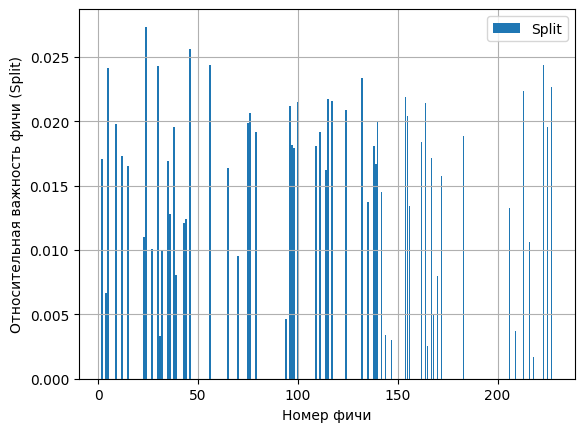

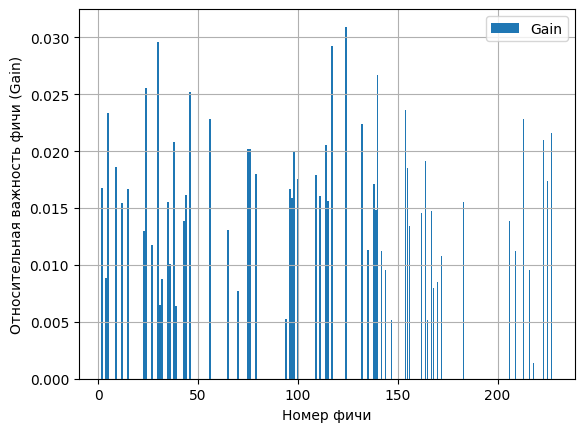

In [293]:
space = [int(feature[-4:].split('_')[1]) for feature in train_data_df[features_optuna].columns]
split_importance = model_lgb.feature_importance(importance_type='split')
plt.bar(space, split_importance / sum(split_importance), label = 'Split')
plt.xlabel("Номер фичи")
plt.ylabel("Относительная важность фичи (Split)")
plt.grid()
plt.legend()
plt.show()

gain_importance = model_lgb.feature_importance(importance_type='gain')
plt.bar(space, gain_importance / sum(gain_importance), label = 'Gain')
plt.xlabel("Номер фичи")
plt.ylabel("Относительная важность фичи (Gain)")
plt.grid()
plt.legend()
plt.show()

**Вопрос:** Какие выводы можно сделать из полученных графиков?

И по gain, и по split фичи имеют примерно одинаковую важность, отличаются пики, но визуально картина примерно одинаковая: в районе 220 есть признак, у которого наименьшая важность по обоим методам среди других признаков, наибольшую важность по гейну имеет признак в районе 125, когда по сплиту наиболее важный признак находится в районе 25.

# Логрег

## plot_metric_time (1 балл)

**Задание:** Реализуйте функцию plot_metric_time, которая будет принимать на вход четыре аргумента, а именно: 
- массив значений фичи, 
- массив значений таргета,
- массив времени (аггрегированного по месяцам или кварталам, то есть `month` или `quarter` в вашей задаче, по дням рисовать не надо),
- метрику, которую необходимо отрисовать (нужно реализовать функцию для двух метрик: `IV` и `roc_auc`)
- число бакетов для вычисления `IV`, если выбрана эта метрика

Можете добваить какие-то ещё аргументы, если вам нужно

Если в фиче есть пропуски, функция должна убирать строки с пропусками из рассмотрения

**Hint**: можно, конечно, реализовать эту функцию через цикл, а можно попробовать разобраться и реализовать её через пандасовские `groupby` -> `apply`, это изящнее и быстрее

In [294]:
import plotly.graph_objects as go

In [295]:
def plot_metric_time(
        values: pd.Series,
        target: pd.Series,
        time: pd.Series,
        metric: str = 'IV',
        n_buckets_for_IV: int = 15,
        date_or_quarter : str = 'date',
        show_or_return : str = 'show'
) -> go.Figure:
    
    if date_or_quarter not in ['date', 'quarter']:
        raise NotImplementedError("Pass either date or quarter")

    if show_or_return not in ['show', 'return']:
        raise NotImplementedError("Pass either show or return")
    
    feature = values.name
    time.name = date_or_quarter
    values = pd.concat([values, target, time], axis = 1)
    values = values.dropna()
    proper_values = values 

    if metric == 'IV':
        res = proper_values.groupby(by = date_or_quarter).apply(lambda x: calc_IV(x[feature], x['target'], n_buckets_for_IV), include_groups = False)
    elif metric == 'roc_auc':
       res = proper_values.groupby(by = date_or_quarter).apply(lambda x: roc_auc_score(x['target'], x[feature]), include_groups = False)
    else:
        raise NotImplementedError("only 'IV' and 'roc_auc' metrics are implemented")

    # your code here

    plot_title = f'{feature}, {metric} in time'
    fig = go.Figure()
    fig.add_trace(
        go.Scatter(
            x= res.index, # месяцы или кварталы, your code here
            y= res.values, # аггрегированное значение метрики, your code here
            mode='markers+lines',
            name=feature# имя фичи, your code here
            ))
    fig.update_layout(
            title_text=plot_title,
            yaxis=dict(title=metric),
            width=1000,
            height=450,
            xaxis=dict(
                domain=[0, .95],
                showgrid=True,
                tickvals=res.index  # месяцы или кварталы, your code here
                ),
            margin=dict(l=30, r=30, b=30, t=50),
            )
    if show_or_return == 'show':
        fig.show()
    else:
        return fig

In [303]:
# примерно так это должно будет выглядеть
plot_metric_time(df['feature_52'], df['target'], df['quarter']) 

**Задание:** Возьмите **топ-15** фичей получившегося бустинга по важности по `gain`. Отрисуйте для них графики стабильности по `IV` во времени и удалите из рассмотрения те признаки, качество которых деградирует

**NB!** Обращайте внимание на масштаб оси *y!* Иногда признак стабильнее, чем кажется)

Если вам это мешает, можете поменять ось *y*, чтобы она начиналась от нуля в прошлом задании.

In [301]:
# your code here
top_15_idxs = np.argsort(gain_importance)[-15:]
top_15_features = [features_optuna[idx] for idx in top_15_idxs] [::-1]

In [304]:
for feature in top_15_features: 
    plot_metric_time(train_data_df[feature], target_train, train_data_df['quarter'])

**Список деградирующих фичей:**

132, 223.
Так как остальные признаки либо колеблются, либо держутся примерно в одних и тех же значениях, либо показывают +- стабильный рост, только эти фичи показывает какую-то деградацию.

На этом моменте предлагаю сделать новый маленький датафрейм, чтобы не "портить" исходный

И проводить все манипуляции с фичами на нём

In [311]:
top15features_stable = [feature for feature in top_15_features if feature not in ['feature_132', 'feature_223']]

df_for_logreg = df[top15features_stable + ['date', 'month', 'quarter', 'target', 'sample_part']]
top15features_stable

['feature_124',
 'feature_30',
 'feature_117',
 'feature_140',
 'feature_24',
 'feature_46',
 'feature_154',
 'feature_5',
 'feature_213',
 'feature_56',
 'feature_227',
 'feature_38',
 'feature_114']

## Предобработка признаков (3 балла)

**Задание:** Используя функицю woe_line из ДЗ по логрегу, проверьте **числовые** фичи из полученного списка фичей на линейность по WoE на трейн-выборке (если в фиче есть пропуски - дропаем их при отрисовке)

Если фичи нелинейные, **линеаризуйте их**.

Преобразования, которые можно/стоит пробовать:
- клипы (`np.clip`) - зачастую их достаточно
- корень
- квадрат
- логарифм

Если нужно, можно прибавлять к фиче константу или менять её знак

При желании можно "распилить фичу на две половины" (если она немонотонна) и линеаризовать их по отдельности

Однако слишком упираться в линеаризацию фичей не нужно. Если фича ну совсем никак не линеаризуется, в крайнем случае можно её дропнуть или оставить как есть.

При отрисовке можно ограничиться 15-20 бактеами

In [307]:
# your code here
from typing import Tuple
from sklearn.linear_model import LogisticRegression
import scipy.stats as sps

def make_figure(buckets_info : dict, plot_title : str) -> go.Figure:
    """Строит график линейности."""
    fig = go.Figure()

    # общие настройки
    title = dict(
        text=plot_title,
        y=0.95,
        x=0.5,
        font=dict(size=12),
        xanchor="center",
        yanchor="top"
    )
    margin = go.layout.Margin(
        l=50,
        r=50,
        b=50,
        t=60
    )

    fig.add_trace(
        go.Scatter(
            x=buckets_info["mean_feature"],
            y=buckets_info["line"],
            mode='lines',
            name="interpolation_line",
            showlegend=False
        )
    )

    fig.add_trace(
        go.Scatter(
            x=buckets_info["mean_feature"],
            y=buckets_info["woe"],
            line=dict(
                color='firebrick',
                width=1,
                dash='dot'
            ),
            error_y=dict(
                type='data',
                symmetric=False,
                array=buckets_info["woe_upper"] - buckets_info["woe"],
                arrayminus=buckets_info["woe"] - buckets_info["woe_lower"]
            ),
            name="WoE",
            showlegend=False)
    )

    fig.update_layout(
        width=1000,
        height=450,
        xaxis_title=dict(
            text='Feature value',
            font=dict(size=12)
        ),
        yaxis_title=dict(
            text="WoE",
            font=dict(size=12)
        ),
        title=title,
        margin=margin
    )

    return fig

def calc_line(values : np.ndarray, target : np.ndarray, mean_feature : np.ndarray, offset : float) -> np.ndarray:
    """Строим линейную интерполяцию для WoE."""

    # строим логистическую регрессию на одном признаке
    # и считаем ее предсказания в точках – mean_feature

    model = LogisticRegression()
    model = model.fit(values.reshape(-1, 1), target) # reshape, иначе ругается sklearn

    # .predict_proba возвращает матрицу (n_samples, n_classes)
    # простыми словами он возращает матрицу вида:
    # (P(y = 0 | x_1), P(y = 1 | x_1))
    # (...)
    # (P(y = 0 | x_n), P(y = 1 | x_n))
    # Так как в логреге мы интересуемся P(y = 1 | X), 
    # то и берём мы только второй столбец.

    proba = model.predict_proba(mean_feature.reshape(-1, 1))[:, 1]
    line = woe_transform(proba, offset)
    return line

def woe_ci(target : np.ndarray, buckets : np.ndarray, offset : float) -> Tuple[pd.Series]:
    """Для каждого бакета вычисляем WoE и доверительный
    интервал для него."""
    # считаем бэдрейт и доверительный интервал для него (любым способом)
    badrate, badrate_lower, badrate_upper = pd.Series([]), pd.Series([]), pd.Series([])
    for bucket in sorted(set(buckets)):
        badrate[bucket] = target[buckets == bucket].mean()
        add_val = sps.norm.ppf(1 - 0.05 / 2, loc = 0, scale = 1) * ((badrate[bucket]) * (1 - badrate[bucket]) / len(target[buckets == bucket]))**0.5
        badrate_lower[bucket] =  badrate[bucket] - add_val
        badrate_upper[bucket] =  badrate[bucket] + add_val

    # переходим от бэдрейта к woe
    woe, woe_lower, woe_upper = pd.Series([]), pd.Series([]), pd.Series([])
    for bucket in sorted(set(buckets)):
            woe[bucket] = woe_transform(badrate=badrate[bucket], offset=offset)
            woe_lower[bucket] = woe_transform(badrate = badrate_lower[bucket], offset = offset)
            woe_upper[bucket] = woe_transform(badrate = badrate_upper[bucket], offset=offset)
    return woe, woe_lower, woe_upper

def calc_buckets_info(values : np.ndarray, target : np.ndarray, buckets : np.ndarray) -> dict:
    """Для каждого бакета расчитывает
     - среднее значение признака
     - линейную интерполяцию в пространстве woe
     - значение woe и доверительный интервал для него"""

    mean_feature = np.array([values[buckets == i].mean() for i in sorted(set(buckets))])
    offset = logit(target.mean())
    woe, woe_lower, woe_upper = woe_ci(target, buckets, offset)
    buckets_info = {
        "mean_feature" : mean_feature,
        "line"         : calc_line(values, target, mean_feature, offset),
        "woe"          : woe,
        "woe_lower"    : woe_lower,
        "woe_upper"    : woe_upper
    }

    return buckets_info

def calc_plot_title(
        values : np.ndarray,
        target : np.ndarray,
        buckets : np.ndarray
    ) -> str:
    """Считает для признака roc auc, IV, R^2"""
    auc = roc_auc_score(target, values)

    # формула выше
    total = len(target)
    bads = target.sum()
    goods = total - bads
    offset = logit(target.mean())
    IV = sum(
            [
            ((bads_i := target[buckets == i].sum()) / bads - ((m := len(target[buckets == i])) - bads_i) / goods) * 
            woe_transform(bads_i / m, offset)   for i in sorted(set(buckets))
            ]
        ) # простите за это..

    # Взвешенный R^2 
    # X - среднее в бакете, Y - woe в бакете, вес – число наблюдений в бакете

    # Будем считать как квадрат корреляции, потому что здесь -
    # https://en.wikipedia.org/wiki/Coefficient_of_determination
    # - так написано, а кто я такой, чтобы не верить?

    X_arr = []
    w_arr = []
    woe_buck, _, _ = woe_ci(target, buckets, offset)
    woe_buck = np.asarray(woe_buck)
    
    for i in sorted(set(buckets)):
        bucket = target[buckets == i]
        X_arr.append(values[buckets == i].mean())
        w_arr.append(len(bucket))

    w_arr = np.array(w_arr)
    X_arr = np.array(X_arr)

    w_s = w_arr.sum()
    X_w_mean = np.sum([w_arr[i] * X_arr[i] for i in range(len(set(buckets)))]) / w_s
    Y_w_mean = np.sum([w_arr[i] * woe_buck[i] for i in range(len(set(buckets)))]) / w_s

    X_arr = X_arr - X_w_mean
    woe_buck = woe_buck - Y_w_mean

    cov = np.sum([w_arr[i] * X_arr[i] * woe_buck[i] for i in range(len(set(buckets)))]) / w_s
    var_x = np.sum([w_arr[i] * X_arr[i] ** 2 for i in range(len(set(buckets)))]) / w_s
    var_y = np.sum([w_arr[i] * woe_buck[i] ** 2 for i in range(len(set(buckets)))]) / w_s

    R_sqr = cov ** 2 / (var_x * var_y)

    plot_title = (        
        f"AUC = {auc:.3f} "
        f"IV = {IV:.3f} "
        f"R_sqr = {R_sqr:.3f} "
    )

    return plot_title
def woe_line(
        values : np.ndarray,
        target : np.ndarray,
        n_buckets : int
    ) -> go.Figure:
    """График линейности переменной по WoE."""
    buckets : np.ndarray = calc_buckets(values, n_buckets)
    buckets_info : pd.DataFrame = calc_buckets_info(values, target, buckets)
    plot_title : str = calc_plot_title(values, target, buckets)
    fig = make_figure(buckets_info, plot_title)
    return fig

In [310]:
for x in top15features_stable:
    print(train_data_df[x].dtype, x)

float64 feature_124
float64 feature_30
float64 feature_117
float64 feature_140
float64 feature_24
float64 feature_46
float64 feature_154
float64 feature_5
float64 feature_213
float64 feature_56
float64 feature_227
float64 feature_38
float64 feature_114


Видимо придётся проверять все..)

In [309]:
for x in top15features_stable:
    val = train_data_df[x].dropna()
    print(x)
    woe_line(np.asarray(val), np.asarray(target_train[val.index]), 15).show()

feature_124


feature_30


feature_117


feature_140


feature_24


...

feature_213


feature_56


feature_227


feature_38


feature_114


Пришло время заполнить пропуски.

Самый простой вариант для числовых признаков - заполнить их средним значением фичи

**Вопрос**: какие проблемы могут возникнуть при таком заполнении пропусков?

**Задание**: Проверьте, что заполнение средним значением адекватно для тех признаков, где есть пропуски (hint: в нашем датасете - почти всегда адекватно). Если нет, придумайте, как ещё можно заполнить пропуски. Ну и заполните их)

In [19]:
# your code here

Вспомним про категориальные признаки, их нужно закодировать.

**Задание:** Используя `OneHotEncoder` закодируйте категориальные признаки.

In [ ]:
from sklearn.preprocessing import OneHotEncoder

# your code here

## Stepwise и обучение логрега (5 баллов)

**Задание (boss)**: Реализуйте Stepwise-алгоритм.

Ваша функция `stepwise` должна принимать на вход:
- Датафрейм со всеми признаками и таргетом
- список с именами рассматриваемых признаков
- строку-имя таргета
- уровни значимости `alpha_in` и `alpha_out`

И возвращать список отобранных признаков.

Во время работы пусть она также выводит, какой признак был включён или исключён и с каким `p-value`

In [ ]:
from scipy.stats.distributions import chi2
from sklearn.metrics import log_loss

In [ ]:
def likelihood_ratio_test(ll_short, ll_long):
    
    """
    вспомогательная функция
    рассчитывает значение p-value для теста отношения правдоподобия
    ll_short — логарифм правдоподобия модели на k переменных
    ll_long — логарифм правдоподобия модели на k+1 переменной

    Returns
    -----
    p-value
    """
    lr = 2 * (ll_short - ll_long)
    return chi2.sf(lr, 1)

In [ ]:
def stepwise(
        df: pd.DataFrame, 
        features: list[str], 
        target: str, 
        alpha_in: float = 0.01, 
        alpha_out:  float = 0.05
        ) -> list[str]:
    

    selected_features = list()

    while True:

        # forward:
        best_feature = None
        if (len(selected_features) < len(features)):


            # your code here


            if best_feature:
                selected_features.append(best_feature)
                print(f"В модель была добавлена переменная {best_feature}, p-value: {round(p_value, 6)}")


        # backward
        worst_feature = None
        if (len(selected_features) > 1):


            # your code here


            if worst_feature:
                selected_features.remove(worst_feature)
                print(f"Из модели была удалена переменная {worst_feature}, p-value: {round(p_value, 6)}")

        if not (best_feature or worst_feature):
            break # но вы можете сформулировать критерий останова по-другому, если вам так будет удобнее писать

    return selected_features

Запустите ваш алгоритм на отобранных фичах со значениями `alpha_in = 0.01`, `alpha_out = 0.02`

Если в степвайз заходят *все переменные*, причём с очень маленькими `p-value` - это неудивительно, ведь вы уже провели серьёзный предварительный отбор фичей.

Чтобы убедиться в коректности работы своего алгоритма, можете попробовать запустить его на каких-нибудь других фичах, откинутых сильно ранее

In [ ]:
selected_features = stepwise(..., ..., ..., alpha_in = 0.01, alpha_out = 0.02)

**Задание**: На получившемся наборе признаков обучим, наконец, логрег!

Для обучения можно использовать трейн + валидацию вместе, либо просто трейн

*Не забудьте отскалировать фичи*

In [ ]:
from sklearn.preprocessing import StandardScaler # Или другой скейлер
from sklearn.linear_model import LogisticRegression
from scipy.special import logit

In [ ]:
scaler = StandardScaler()
scaler.fit(...)
# your code here
logreg = LogisticRegression(penalty=None)
logreg.fit(...)
df_for_logreg['logreg'] = logreg.predict_proba(...)[:, 1]
df_for_logreg['logit_logreg'] = logit(df_for_logreg['logreg'])

**Задание:** Оцените качество получившегося логрега **на тестовой выборке** по метрике `roc_auc`. 

**Ваша задача - побить** `threshold_auc = 0.622`. Если этого сделать ну совсем не получается, попробуйте добавить в модель ещё переменных (но должно получаться :)

**Также:**

- Постройте графики линейности по WoE получившегося логрега на трейне и тестовой выборке (оценивайте линейность для `logit_logreg`, а не для вероятности!)
- Постройте график стабильности `roc_auc` во времени для получившегося логрега

In [ ]:
# your code here

**Задание:** Визуализируйте важность фичей полученной линейной модели.

In [ ]:
# your code here

# Бонусная часть (4 балла)

В разделе про бустинг мы обучали `LGBMClassifier` на довольно большом наборе фичей. Их количество можно сократить, при этом не теряя в качестве модели.

За начальный набор признаков можно взять все признаки (все 230) или признаки после отбора по IV.

**Ваша задача:** Отобрать признаки, подобрать оптимальные гиперпараметры и обучить `LGBMClassifier`.

Задание творческое) Можно использовать любые методы отбора признаков / оптимизации гиперпараметров.

**Чем меньше признаков, без ухудшения качества модели – тем лучше.**

In [ ]:
# your code here

Идеи для отбора признаков:

- Воспользоваться методами из модуля `sklearn.feature_selection` (точно можно попробовать RFE). Документация https://scikit-learn.org/stable/modules/feature_selection.html
<!-- - С помощью `BorutaPy` из библиотеки `boruta` (https://towardsdatascience.com/simple-example-using-boruta-feature-selection-in-python-8b96925d5d7a – статья может помочь разобраться с запуском алгоритма (мб не откроется без vpn)) -->
- permutation importance и elimination по нему (https://scikit-learn.org/stable/modules/permutation_importance.html)
- попробовать использовать shap-values

In [ ]:
# your answere here